In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv("../data/train.csv")

In [3]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
train.shape

(10886, 12)

In [5]:
train.columns

Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count'],
      dtype='str')

In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  str    
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 1.2 MB


In [7]:
train.isnull().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

In [8]:
train.duplicated().sum()

np.int64(0)

In [9]:
train.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


In [10]:
train["count"].describe()

count    10886.000000
mean       191.574132
std        181.144454
min          1.000000
25%         42.000000
50%        145.000000
75%        284.000000
max        977.000000
Name: count, dtype: float64

In [11]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

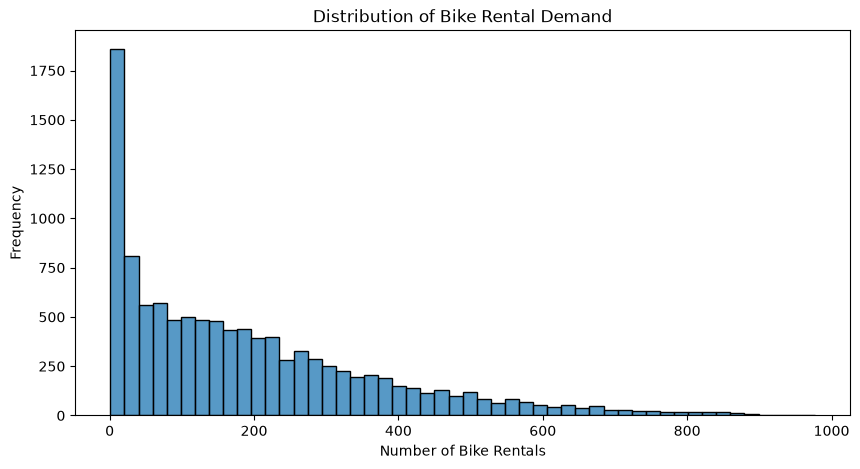

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(train["count"], bins=50)

plt.title("Distribution of Bike Rental Demand")
plt.xlabel("Number of Bike Rentals")
plt.ylabel("Frequency")

plt.show()

In [13]:
(train["casual"] + train["registered"] == train["count"]).all()

np.True_

In [14]:
train["season"].value_counts().sort_index()

season
1    2686
2    2733
3    2733
4    2734
Name: count, dtype: int64

In [15]:
train["holiday"].value_counts()

holiday
0    10575
1      311
Name: count, dtype: int64

In [16]:
train["workingday"].value_counts()

workingday
1    7412
0    3474
Name: count, dtype: int64

In [17]:
train["weather"].value_counts().sort_index()

weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64

In [18]:
train["weather"].value_counts().sort_index()

weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64

In [19]:
train["hour"] = pd.to_datetime(train["datetime"]).dt.hour

In [20]:
hourly_demand = train.groupby("hour")["count"].mean()
hourly_demand

hour
0      55.138462
1      33.859031
2      22.899554
3      11.757506
4       6.407240
5      19.767699
6      76.259341
7     213.116484
8     362.769231
9     221.780220
10    175.092308
11    210.674725
12    256.508772
13    257.787281
14    243.442982
15    254.298246
16    316.372807
17    468.765351
18    430.859649
19    315.278509
20    228.517544
21    173.370614
22    133.576754
23     89.508772
Name: count, dtype: float64

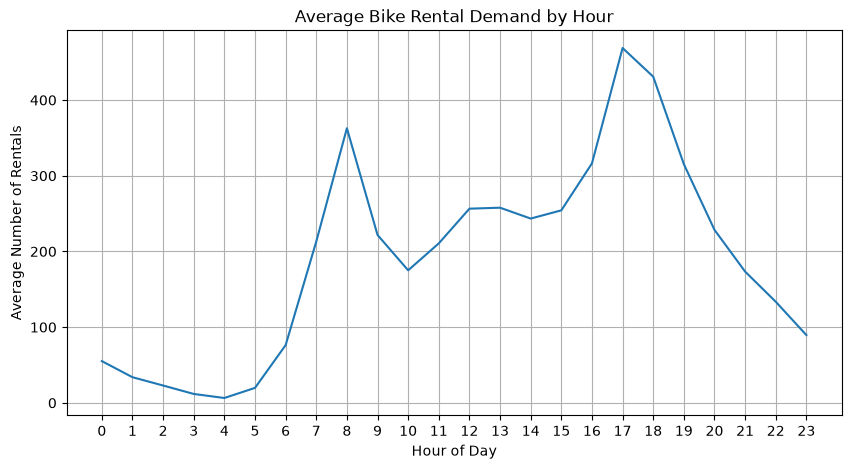

In [21]:
plt.figure(figsize=(10, 5))

hourly_demand.plot()

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid()
plt.show()

In [22]:
workingday_demand = train.groupby("workingday")["count"].mean()

workingday_demand

workingday
0    188.506621
1    193.011873
Name: count, dtype: float64

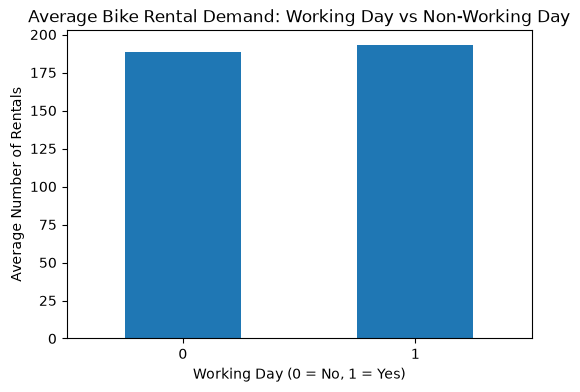

In [23]:
plt.figure(figsize=(6, 4))

workingday_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand: Working Day vs Non-Working Day")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Average Number of Rentals")

plt.xticks(rotation=0)
plt.show()

In [24]:
weather_demand = train.groupby("weather")["count"].mean()

weather_demand

weather
1    205.236791
2    178.955540
3    118.846333
4    164.000000
Name: count, dtype: float64

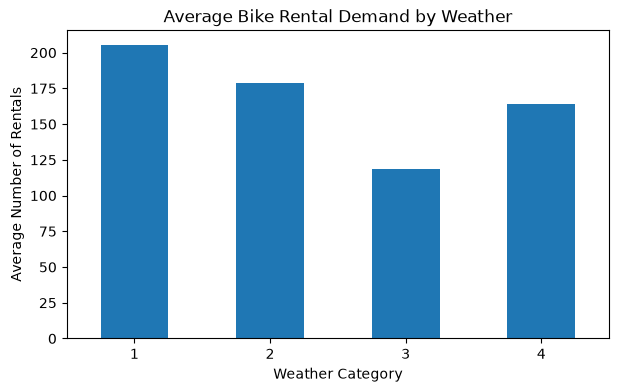

In [25]:
plt.figure(figsize=(7, 4))

weather_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand by Weather")
plt.xlabel("Weather Category")
plt.ylabel("Average Number of Rentals")

plt.xticks(rotation=0)
plt.show()

In [26]:
season_demand = train.groupby("season")["count"].mean()

season_demand

season
1    116.343261
2    215.251372
3    234.417124
4    198.988296
Name: count, dtype: float64

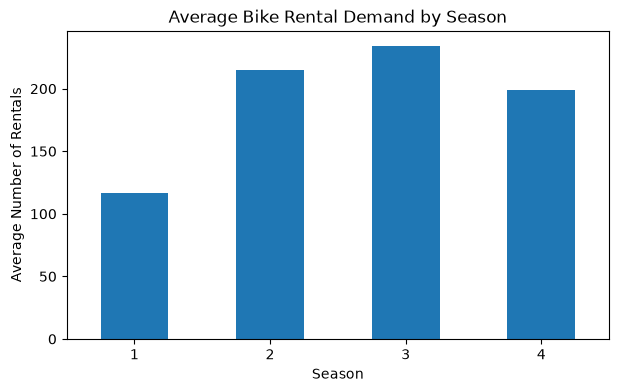

In [27]:
plt.figure(figsize=(7, 4))

season_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Number of Rentals")

plt.xticks(rotation=0)
plt.show()

In [28]:
train["month"] = pd.to_datetime(train["datetime"]).dt.month

In [29]:
monthly_demand = train.groupby("month")["count"].mean()
monthly_demand

month
1      90.366516
2     110.003330
3     148.169811
4     184.160616
5     219.459430
6     242.031798
7     235.325658
8     234.118421
9     233.805281
10    227.699232
11    193.677278
12    175.614035
Name: count, dtype: float64

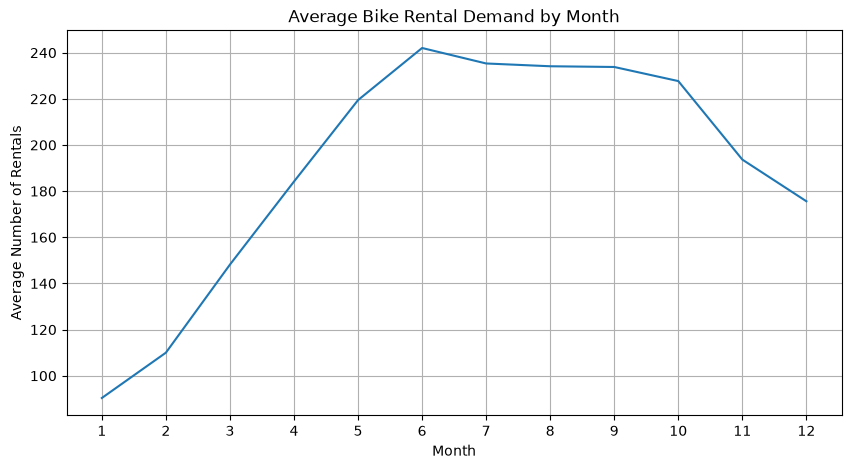

In [30]:
plt.figure(figsize=(10, 5))

monthly_demand.plot()

plt.title("Average Bike Rental Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Number of Rentals")

plt.xticks(range(1, 13))
plt.grid()
plt.show()

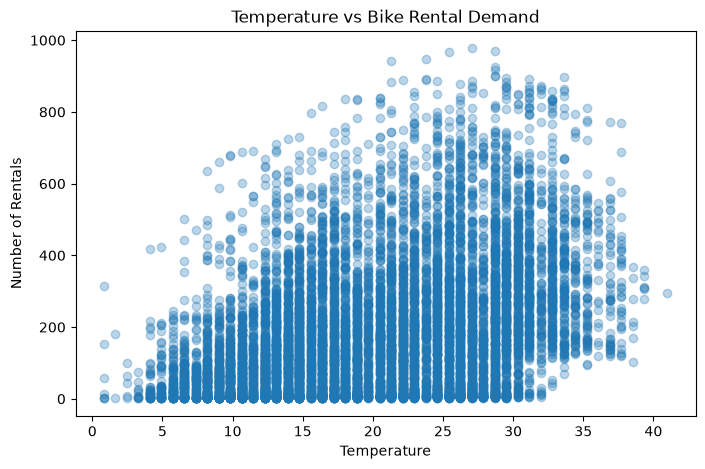

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(train["temp"], train["count"], alpha=0.3)

plt.title("Temperature vs Bike Rental Demand")
plt.xlabel("Temperature")
plt.ylabel("Number of Rentals")

plt.show()

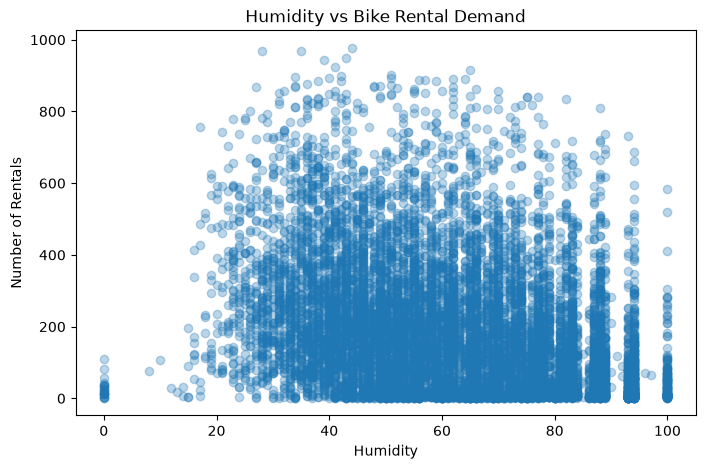

In [32]:
plt.figure(figsize=(8, 5))

plt.scatter(train["humidity"], train["count"], alpha=0.3)

plt.title("Humidity vs Bike Rental Demand")
plt.xlabel("Humidity")
plt.ylabel("Number of Rentals")

plt.show()

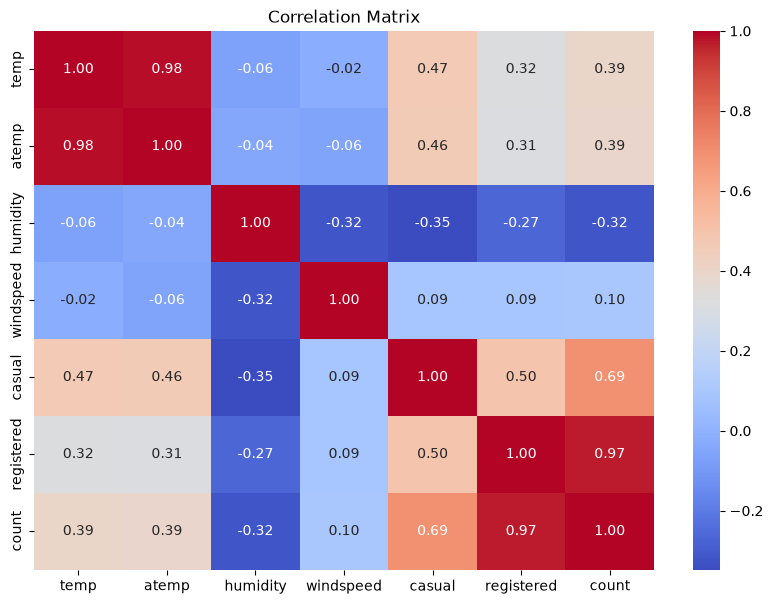

In [33]:
numeric_cols = [
    "temp",
    "atemp",
    "humidity",
    "windspeed",
    "casual",
    "registered",
    "count"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    train[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

In [35]:
train.shape

(10886, 14)